C:\Users\cvais\AppData\Local\Temp\ipykernel_22708\3938890011.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, cnx)


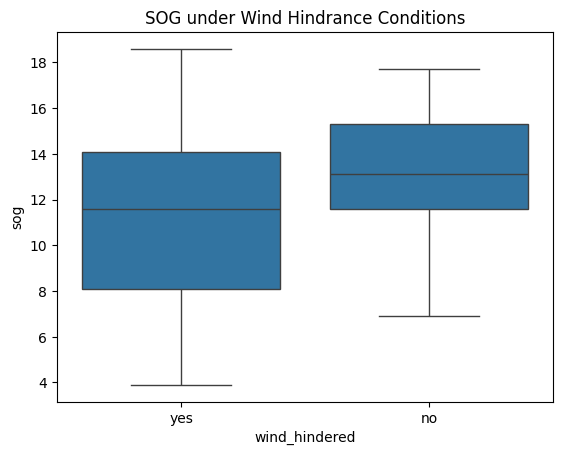

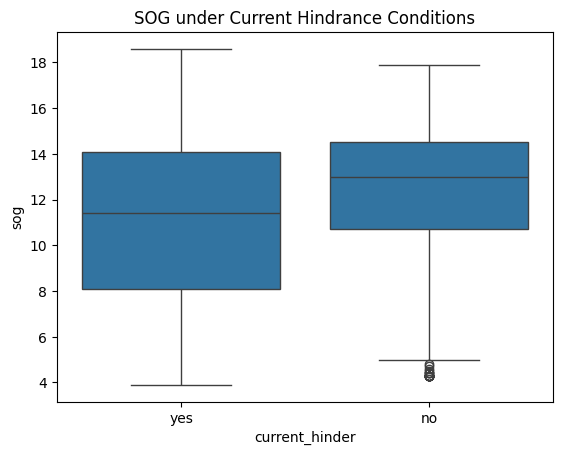

In [1]:
import mysql.connector
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# DB config
db_config = {
    "host": "localhost",
    "user": "root",
    "password": "AMS_ship_traj03",
    "database": "ship_data",
}

# Helper to query MySQL
def load_query(query):
    cnx = mysql.connector.connect(**db_config)
    df = pd.read_sql(query, cnx)
    cnx.close()
    return df

query = """
SELECT sog, wind_hindered, current_hinder,cog
FROM ais_open_water_polygon_env
WHERE sog IS NOT NULL AND wind_hindered IS NOT NULL AND current_hinder IS NOT NULL and ship_type between 60 and 80
and navigational_status = 0 and visibility > 2000
"""
df = load_query(query)
df["direction"] = df["cog"].apply(lambda x: "inbound" if 180 <= x <= 360 else "outbound")
sns.boxplot(data=df, x="wind_hindered", y="sog")
plt.title("SOG under Wind Hindrance Conditions")
plt.show()

sns.boxplot(data=df, x="current_hinder", y="sog")
plt.title("SOG under Current Hindrance Conditions")
plt.show()



Speed Drop (ΔSOG) Relative to Unhindered

In [2]:
grouped = df.groupby(["wind_hindered", "current_hinder"])["sog"].agg(["mean", "count"]).reset_index()
unhindered_mean = grouped.query("wind_hindered == 'no' and current_hinder == 'no'")["mean"].values[0]
grouped["delta_sog"] = grouped["mean"] - unhindered_mean
grouped


,wind_hindered,current_hinder,mean,count,delta_sog
0,no,no,12.442456,1246,0.000000
1,no,yes,13.253139,2469,0.810683
2,yes,no,12.580587,5311,0.138132
3,yes,yes,10.826050,13432,-1.616406


Delta sog and cog wrt direction

In [ ]:

grouped = df.groupby(["wind_hindered", "current_hinder", "direction"])["sog"].agg(["mean", "count"]).reset_index()

# Get baseline mean per direction (only rows with no hindrance)
baseline_df = (
    grouped
    .query("wind_hindered == 'no' and current_hinder == 'no'")
    [['direction', 'mean']]
    .rename(columns={'mean': 'baseline_mean'})
)

grouped = grouped.merge(baseline_df, on='direction', how='left')

# Calculate delta_sog relative to direction-specific baseline
grouped['delta_sog'] = grouped['mean'] - grouped['baseline_mean']

# Print the final table
print(grouped)




  wind_hindered current_hinder direction       mean  count  baseline_mean  \
0            no             no   inbound  16.561421    197      16.561421   
1            no             no  outbound  11.668923   1049      11.668923   
2            no            yes   inbound  10.692842    475      16.561421   
3            no            yes  outbound  13.863039   1994      11.668923   
4           yes             no   inbound  11.296627    830      16.561421   
5           yes             no  outbound  12.818411   4481      11.668923   
6           yes            yes   inbound  11.759340   8116      16.561421   
7           yes            yes  outbound   9.401185   5316      11.668923   

   delta_sog  
0   0.000000  
1   0.000000  
2  -5.868579  
3   2.194116  
4  -5.264795  
5   1.149488  
6  -4.802082  
7  -2.267738  


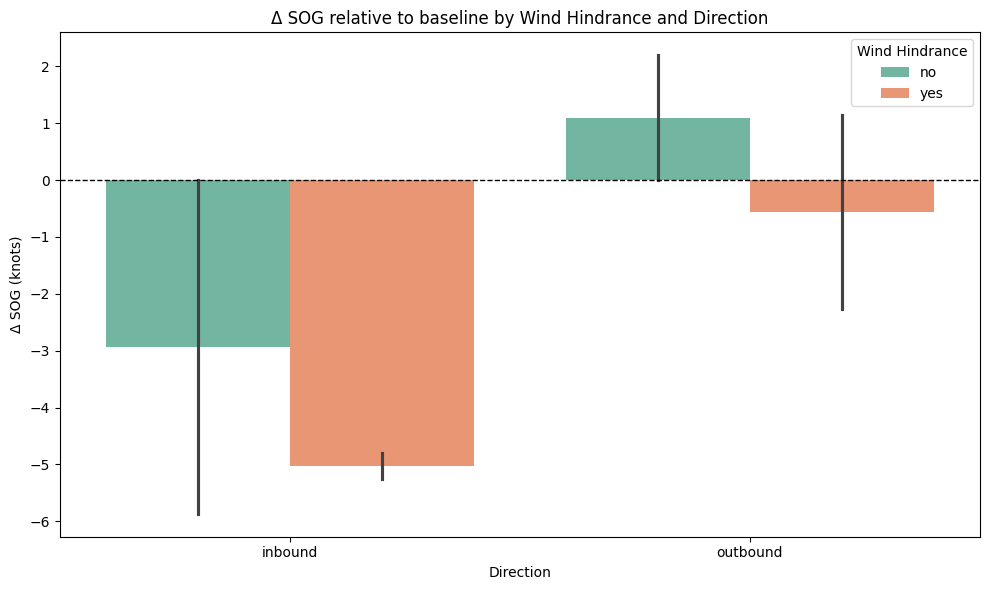

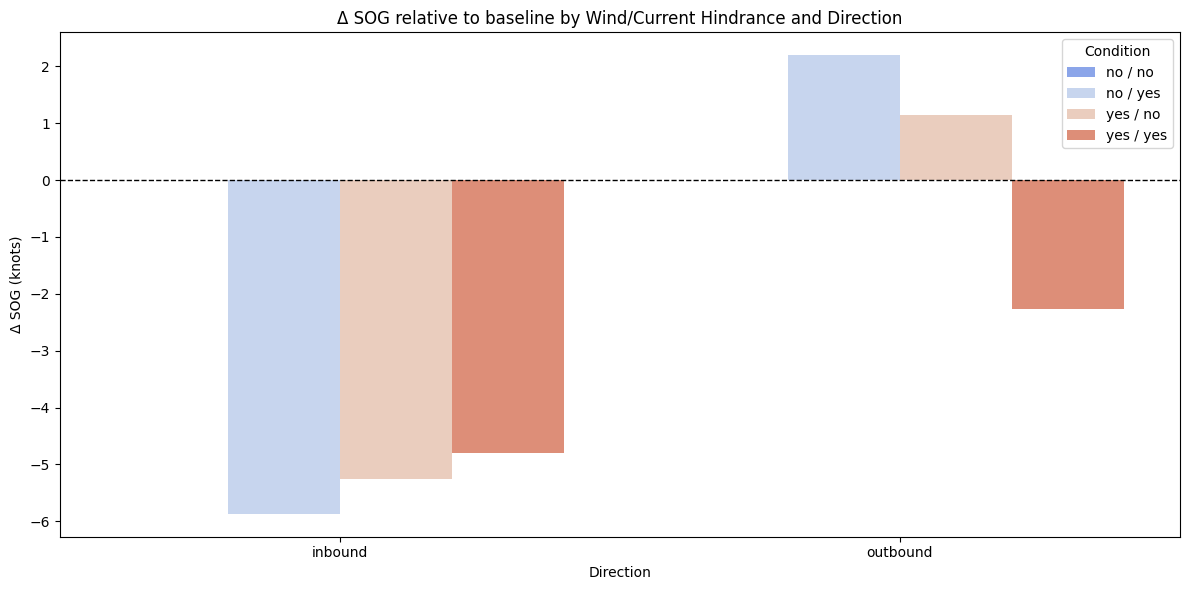

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Barplot of delta SOG by hindrance condition and direction
plt.figure(figsize=(10,6))
sns.barplot(
    data=grouped,
    x="direction",
    y="delta_sog",
    hue="wind_hindered",
    palette="Set2",
    dodge=True
)
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.title("Δ SOG relative to baseline by Wind Hindrance and Direction")
plt.ylabel("Δ SOG (knots)")
plt.xlabel("Direction")
plt.legend(title="Wind Hindrance")
plt.tight_layout()
plt.show()


grouped['condition'] = (
    grouped['wind_hindered'].astype(str) + " / " + grouped['current_hinder'].astype(str)
)

plt.figure(figsize=(12,6))
sns.barplot(
    data=grouped,
    x="direction",
    y="delta_sog",
    hue="condition",
    palette="coolwarm"
)
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.title("Δ SOG relative to baseline by Wind/Current Hindrance and Direction")
plt.ylabel("Δ SOG (knots)")
plt.xlabel("Direction")
plt.legend(title="Condition")
plt.tight_layout()
plt.show()


In [10]:
# Group by hindrance + direction and calculate median and count
grouped = (
    df.groupby(["wind_hindered", "current_hinder", "direction"])["sog"]
      .agg(median="median", count="count")
      .reset_index()
)

# Get baseline median per direction under no hindrance
baseline_df = (
    grouped
    .query("wind_hindered == 'no' and current_hinder == 'no'")
    [['direction', 'median']]
    .rename(columns={'median': 'baseline_median'})
)

# Merge baseline back onto grouped by direction
grouped = grouped.merge(baseline_df, on='direction', how='left')

# Calculate delta relative to each direction's baseline
grouped['delta_sog'] = grouped['median'] - grouped['baseline_median']

# Print result
print(grouped)

  wind_hindered current_hinder direction  median  count  baseline_median  \
0            no             no   inbound    17.2    197             17.2   
1            no             no  outbound    12.2   1049             12.2   
2            no            yes   inbound    10.9    475             17.2   
3            no            yes  outbound    14.3   1994             12.2   
4           yes             no   inbound    11.5    830             17.2   
5           yes             no  outbound    13.7   4481             12.2   
6           yes            yes   inbound    12.4   8116             17.2   
7           yes            yes  outbound     8.9   5316             12.2   

   delta_sog  
0        0.0  
1        0.0  
2       -6.3  
3        2.1  
4       -5.7  
5        1.5  
6       -4.8  
7       -3.3  


SOG by Wind Hindrance and Direction

C:\Users\cvais\AppData\Local\Temp\ipykernel_8088\3938890011.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, cnx)


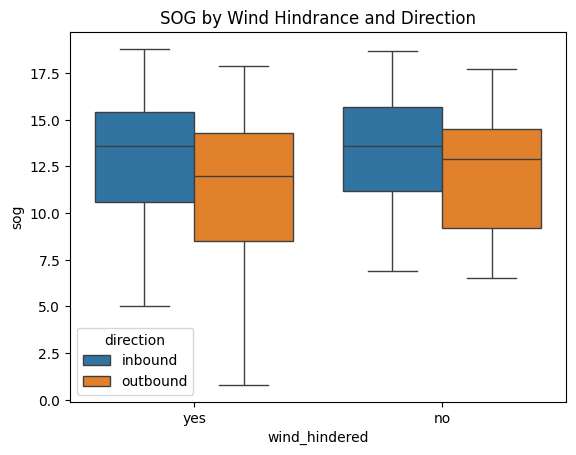

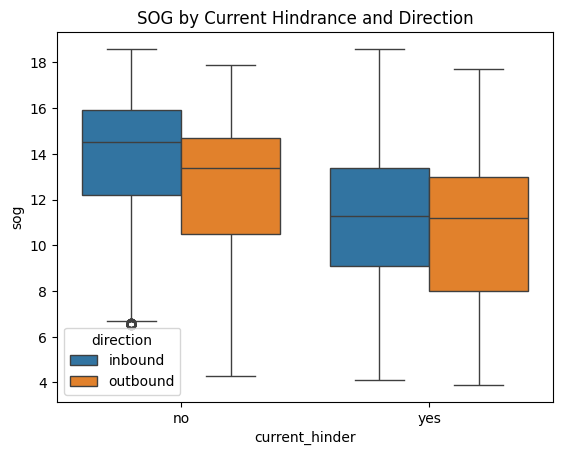

In [5]:
query = """
SELECT sog, cog, wind_hindered, current_hinder
FROM ais_open_water_polygon_env
WHERE sog IS NOT NULL AND cog IS NOT NULL and ship_type between 60 and 80
and navigational_status = 0;
"""
df = load_query(query)
df["direction"] = df["cog"].apply(lambda x: "inbound" if 180 <= x <= 360 else "outbound")

sns.boxplot(data=df, x="wind_hindered", y="sog", hue="direction")
plt.title("SOG by Wind Hindrance and Direction")
plt.show()


sns.boxplot(data=df, x="current_hinder", y="sog", hue="direction")
plt.title("SOG by Current Hindrance and Direction")
plt.show()


Wind allignment check

In [8]:
query = """
SELECT sog, cog, wind_direction_10m, wind_hindered, current_hindered
FROM ais_open_water_polygon_env
WHERE sog IS NOT NULL 
  AND cog IS NOT NULL 
  AND wind_direction_10m IS NOT NULL
  AND ship_type BETWEEN 60 AND 80
  AND navigational_status = 0
  and sog<30;
"""
df = load_query(query)

df.columns = df.columns.str.lower()
df["direction"] = df["cog"].apply(lambda x: "inbound" if 180 <= x <= 360 else "outbound")
print(df.columns)



C:\Users\cvais\AppData\Local\Temp\ipykernel_19296\3938890011.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, cnx)


Index(['sog', 'cog', 'wind_direction_10m', 'wind_hindered', 'current_hindered',
       'direction'],
      dtype='object')


In [9]:
def classify_wind_alignment(cog, wind_dir):
    angle = (wind_dir - cog + 360) % 360
    if angle <= 45 or angle >= 315:
        return "tailwind"
    elif 135 <= angle <= 225:
        return "headwind"
    else:
        return "crosswind"

df["wind_alignment"] = df.apply(lambda r: classify_wind_alignment(r["cog"], r["wind_direction_10m"]), axis=1)


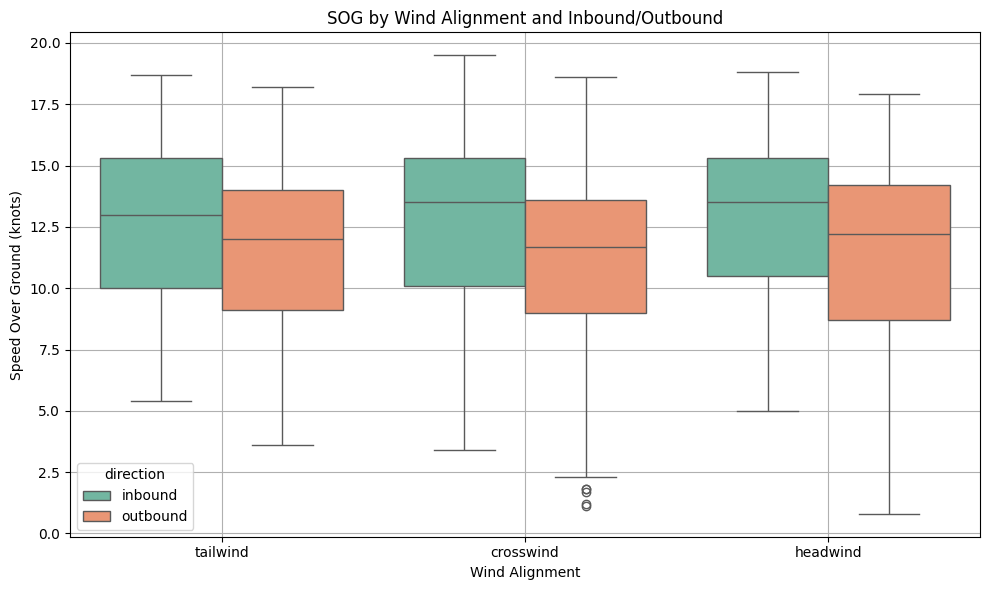

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="wind_alignment", y="sog", hue="direction", palette="Set2")
plt.title("SOG by Wind Alignment and Inbound/Outbound")
plt.ylabel("Speed Over Ground (knots)")
plt.xlabel("Wind Alignment")
plt.grid(True)
plt.tight_layout()
plt.show()


SOG over Time under Wind Hindrance

C:\Users\cvais\AppData\Local\Temp\ipykernel_7488\2745989418.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, cnx)
C:\Users\cvais\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


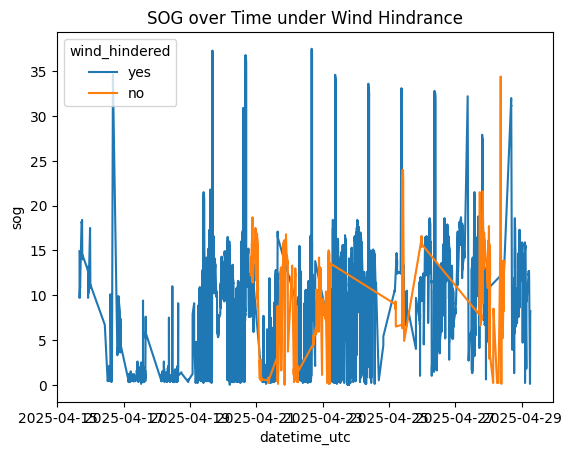

In [ ]:
# SOG over time
query = """
SELECT datetime_utc, sog, wind_hindered
FROM ais_open_water_polygon_env
WHERE datetime_utc IS NOT NULL AND wind_hindered IS NOT NULL and ship_type =70
"""
df = load_query(query)

df["datetime_utc"] = pd.to_datetime(df["datetime_utc"])
sns.lineplot(data=df, x="datetime_utc", y="sog", hue="wind_hindered")
plt.title("SOG over Time under Wind Hindrance")
plt.show()



C:\Users\cvais\AppData\Local\Temp\ipykernel_21052\3938890011.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, cnx)


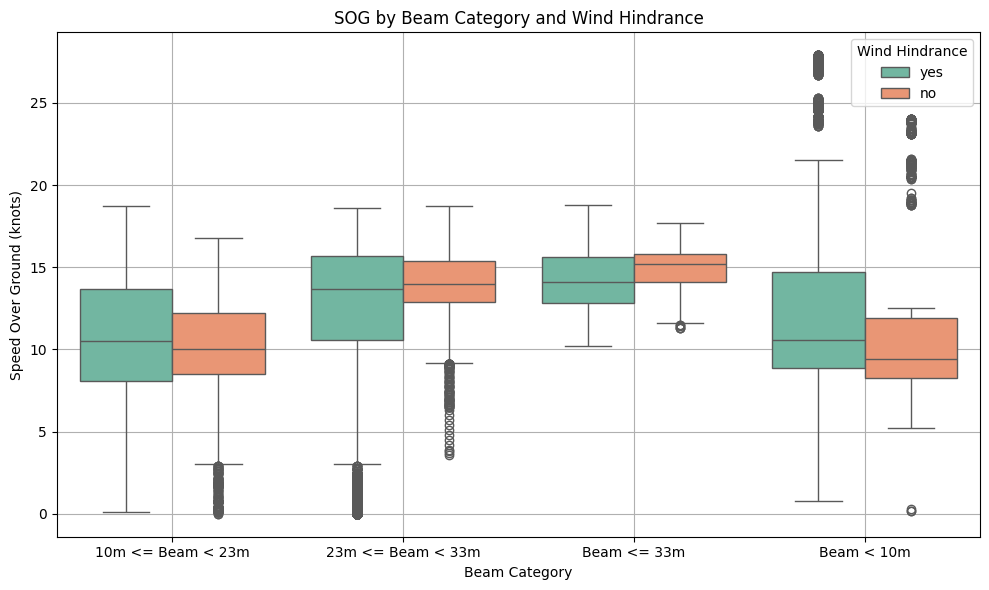

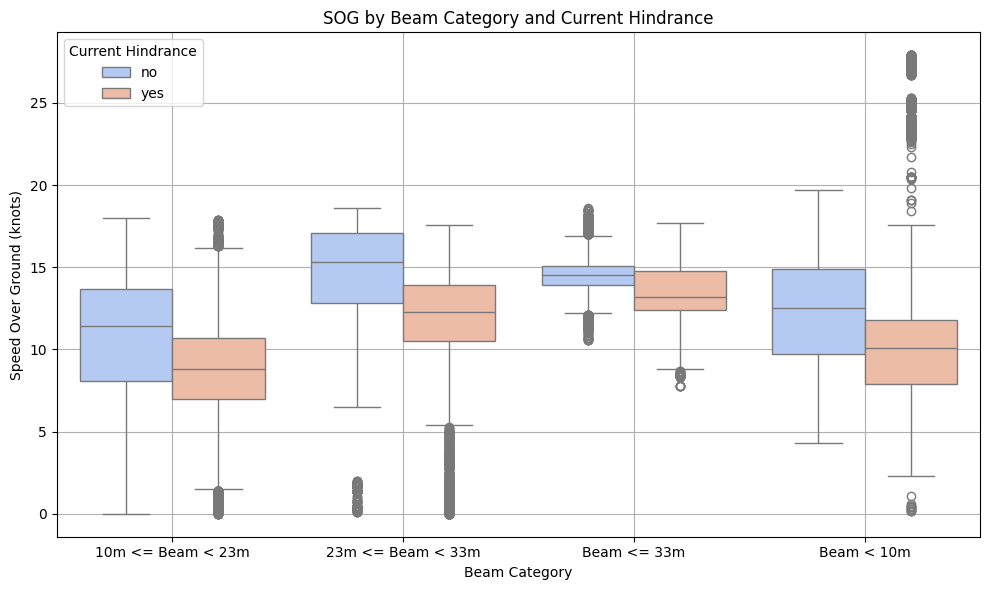


 Median SOG by Beam Category and Wind Hindrance:
wind_hindered        no   yes
beam_category                
10m <= Beam < 23m  10.0  10.5
23m <= Beam < 33m  14.0  13.7
Beam < 10m          9.4  10.6
Beam <= 33m        15.2  14.1

 Median SOG by Beam Category and Current Hindrance:
current_hindered     no   yes
beam_category                
10m <= Beam < 23m  11.4   8.8
23m <= Beam < 33m  15.3  12.3
Beam < 10m         12.5  10.1
Beam <= 33m        14.5  13.2

 Mean SOG by Beam Category and Wind Hindrance:
       beam_category wind_hindered       mean  count
0  10m <= Beam < 23m            no  10.158251   4963
1  10m <= Beam < 23m           yes  10.594727  32924
2  23m <= Beam < 33m            no  13.828882   2434
3  23m <= Beam < 33m           yes  12.222165  15637
4         Beam < 10m            no  11.433412    844
5         Beam < 10m           yes  13.134722   5112
6        Beam <= 33m            no  14.860870   1932
7        Beam <= 33m           yes  14.220969   6772

 Mean SOG b

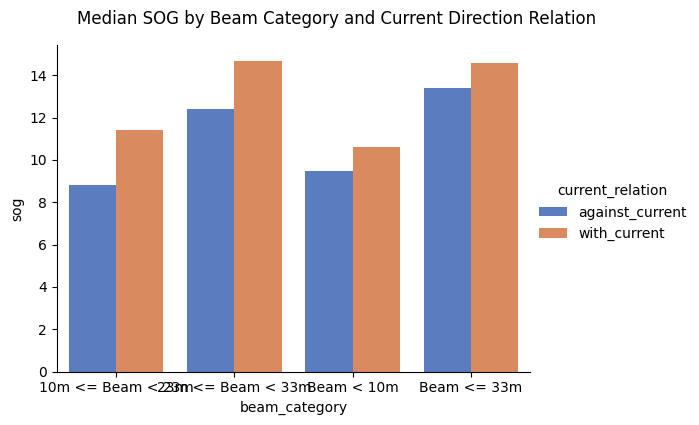

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

query = """
SELECT sog, cog, wind_hindered, current_hindered, beam_category, current_direction_deg
FROM ais_open_water_polygon_env
WHERE sog IS NOT NULL AND beam_category IS NOT NULL 
  AND navigational_status = 0 
  AND sog < 30
"""
df = load_query(query)

# -----------------------------
# CLASSIFY WITH vs AGAINST CURRENT
# -----------------------------
# Compute absolute angle difference between ship course and current direction
df['angle_diff'] = np.abs((df['cog'] - df['current_direction_deg'] + 180) % 360 - 180)

# Label as with_current or against_current
df['current_relation'] = np.where(df['angle_diff'] <= 90, 'with_current', 'against_current')

# -----------------------------
# PLOTS
# -----------------------------

# 1.  Boxplot of SOG vs. Beam Category under Wind Hindrance
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="beam_category", y="sog", hue="wind_hindered", palette="Set2")
plt.title("SOG by Beam Category and Wind Hindrance")
plt.ylabel("Speed Over Ground (knots)")
plt.xlabel("Beam Category")
plt.grid(True)
plt.legend(title="Wind Hindrance")
plt.tight_layout()
plt.show()

# 2.  Boxplot of SOG vs. Beam Category under Current Hindrance
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="beam_category", y="sog", hue="current_hindered", palette="coolwarm")
plt.title("SOG by Beam Category and Current Hindrance")
plt.ylabel("Speed Over Ground (knots)")
plt.xlabel("Beam Category")
plt.grid(True)
plt.legend(title="Current Hindrance")
plt.tight_layout()
plt.show()

# -----------------------------
# SUMMARY TABLES
# -----------------------------
print("\n Median SOG by Beam Category and Wind Hindrance:")
print(df.groupby(["beam_category", "wind_hindered"])["sog"].median().unstack())

print("\n Median SOG by Beam Category and Current Hindrance:")
print(df.groupby(["beam_category", "current_hindered"])["sog"].median().unstack())

print("\n Mean SOG by Beam Category and Wind Hindrance:")
print(df.groupby(["beam_category", "wind_hindered"])["sog"].agg(['mean', 'count']).reset_index())

print("\n Mean SOG by Beam Category and Current Hindrance:")
print(df.groupby(["beam_category", "current_hindered"])["sog"].agg(['mean', 'count']).reset_index())

# -----------------------------
# WITH vs AGAINST CURRENT
# -----------------------------
print("\n Median SOG by Beam Category and Current Relation (With vs Against):")
median_relation = df.groupby(["beam_category", "current_relation"])["sog"].median().unstack()
print(median_relation)

print("\n Mean SOG by Beam Category and Current Relation (With vs Against):")
print(df.groupby(["beam_category", "current_relation"])["sog"].agg(['mean', 'count']).reset_index())

# Calculate Δ (with - against) for medians
median_relation['delta_sog'] = median_relation['with_current'] - median_relation['against_current']
print("\n Δ Median SOG (With - Against) by Beam Category:")
print(median_relation)

# -----------------------------
# PLOT BAR
# -----------------------------
df_plot = df.groupby(["beam_category", "current_relation"])["sog"].median().reset_index()
sns.catplot(
    data=df_plot, x="beam_category", y="sog",
    hue="current_relation", kind="bar", height=4, aspect=1.4, palette="muted"
)
plt.suptitle("Median SOG by Beam Category and Current Direction Relation", y=1.05)
plt.show()



wind direction check

In [13]:
import numpy as np
import pandas as pd


query = """
SELECT sog,cog, wind_hindered, current_hindered, beam_category,wind_direction_10m
FROM ais_open_water_polygon_env
WHERE sog IS NOT NULL AND beam_category IS NOT NULL and ship_type between 60 and 80
and navigational_status = 0
"""
df = load_query(query)

df = df[(df["sog"] >= 3) & (df["sog"] <= 20)]
# Calculate relative wind angle (wind direction relative to vessel course)
df['rel_wind_angle'] = (df['wind_direction_10m'] - df['cog']) % 360

# Convert to -180 to 180 range for better interpretation
df['rel_wind_angle_180'] = df['rel_wind_angle'].apply(lambda x: x - 360 if x > 180 else x)

# Categorize relative wind direction
def categorize_wind_angle(angle):
    if -30 <= angle <= 30:
        return 'Headwind'
    elif 60 <= angle <= 120 or -120 <= angle <= -60:
        return 'Beam wind'
    elif angle >= 150 or angle <= -150:
        return 'Following wind'
    else:
        return 'Other'

df['wind_category'] = df['rel_wind_angle_180'].apply(categorize_wind_angle)

# Group by beam category, wind category, and wind hindrance, then calculate mean SOG and counts
result = df.groupby(['beam_category', 'wind_category', 'wind_hindered']).agg(
    mean_sog = ('sog', 'mean'),
    count = ('sog', 'count')
).reset_index()

print(result)


C:\Users\cvais\AppData\Local\Temp\ipykernel_19296\3938890011.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, cnx)


        beam_category   wind_category wind_hindered   mean_sog  count
0   10m <= Beam < 23m  Following wind           yes  11.173930  17637
1   10m <= Beam < 23m        Headwind            no  10.391998   2012
2   10m <= Beam < 23m           Other            no  11.921035   1526
3   10m <= Beam < 23m           Other           yes  10.311982   5216
4   23m <= Beam < 33m  Following wind           yes  14.487981   7829
5   23m <= Beam < 33m        Headwind            no  13.307777   1363
6   23m <= Beam < 33m           Other            no  16.011207    348
7   23m <= Beam < 33m           Other           yes  14.492767   2461
8          Beam < 10m  Following wind           yes   8.866303    733
9          Beam < 10m        Headwind            no   7.850649     77
10         Beam < 10m           Other            no   7.976190     21
11         Beam < 10m           Other           yes   9.112982    285
12        Beam <= 33m  Following wind           yes  13.957464   4984
13        Beam <= 33

C:\Users\cvais\AppData\Local\Temp\ipykernel_19296\1544825866.py:27: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, cnx)
C:\Users\cvais\AppData\Local\Temp\ipykernel_19296\1544825866.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="visibility_class", y="sog", palette="coolwarm")


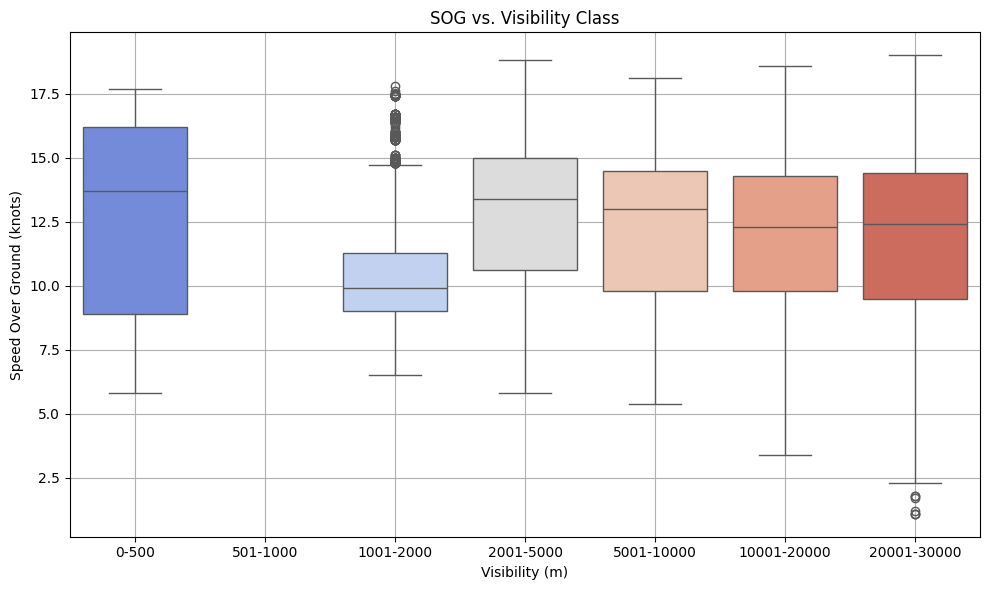


📊 Mean, Median, Count SOG by Visibility Class:
  visibility_class       mean  median  count
0            0-500  12.538657    13.7    551
1        1001-2000  10.890707     9.9   1033
2        2001-5000  12.834113    13.4  15730
3       5001-10000  12.337297    13.0  20310
4      10001-20000  12.169894    12.3  32140
5      20001-30000  12.198560    12.4  35286

🚢 Ship Types in Each Visibility Class:
  visibility_class                            ship_types_present
0            0-500                          [70, 71, 73, 74, 80]
1        1001-2000                      [70, 71, 73, 74, 79, 80]
2        2001-5000              [60, 70, 71, 72, 73, 74, 79, 80]
3       5001-10000  [60, 69, 70, 71, 72, 73, 74, 75, 76, 79, 80]
4      10001-20000      [60, 69, 70, 71, 72, 74, 75, 76, 79, 80]
5      20001-30000  [60, 69, 70, 71, 72, 73, 74, 76, 78, 79, 80]


In [14]:
import mysql.connector
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# --- DB config ---
db_config = {
    "host": "localhost",
    "user": "root",
    "password": "AMS_ship_traj03",
    "database": "ship_data",
}

# --- Load relevant columns with filters ---
def load_visibility_data():
    cnx = mysql.connector.connect(**db_config)
    query = """
        SELECT sog, visibility, beam_category, ship_type, navigational_status
        FROM ais_open_water_polygon_env
        WHERE visibility IS NOT NULL AND sog IS NOT NULL
            AND visibility < 30000 AND sog > 1.0
            AND navigational_status = 0
            AND ship_type BETWEEN 60 AND 80
            and ship_type not in (40,51)
            and sog<30
    """
    df = pd.read_sql(query, cnx)
    cnx.close()
    return df

df = load_visibility_data()

# --- Bin visibility ---
df["visibility_class"] = pd.cut(
    df["visibility"],
    bins=[0, 500, 1000, 2000, 5000, 10000, 20000, 30000],
    labels=["0-500", "501-1000", "1001-2000", "2001-5000", "5001-10000", "10001-20000", "20001-30000"]
)

# --- Plot SOG by visibility class ---
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="visibility_class", y="sog", palette="coolwarm")
plt.title("SOG vs. Visibility Class")
plt.xlabel("Visibility (m)")
plt.ylabel("Speed Over Ground (knots)")
plt.grid(True)
plt.tight_layout()
plt.show()

# --- Grouped stats: mean, median, count ---
group_stats = df.groupby("visibility_class", observed=True)["sog"].agg(['mean', 'median', 'count']).reset_index()
print("\n📊 Mean, Median, Count SOG by Visibility Class:")
print(group_stats)

# --- Ship types per visibility class ---
ship_types_by_bin = df.groupby("visibility_class", observed=True)["ship_type"].apply(lambda x: sorted(x.unique().tolist())).reset_index()
ship_types_by_bin.rename(columns={"ship_type": "ship_types_present"}, inplace=True)
print("\n🚢 Ship Types in Each Visibility Class:")
print(ship_types_by_bin)


Visibility for cargo

C:\Users\cvais\AppData\Local\Temp\ipykernel_19296\3547916292.py:28: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, cnx)
C:\Users\cvais\AppData\Local\Temp\ipykernel_19296\3547916292.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="visibility_class", y="sog", palette="coolwarm")


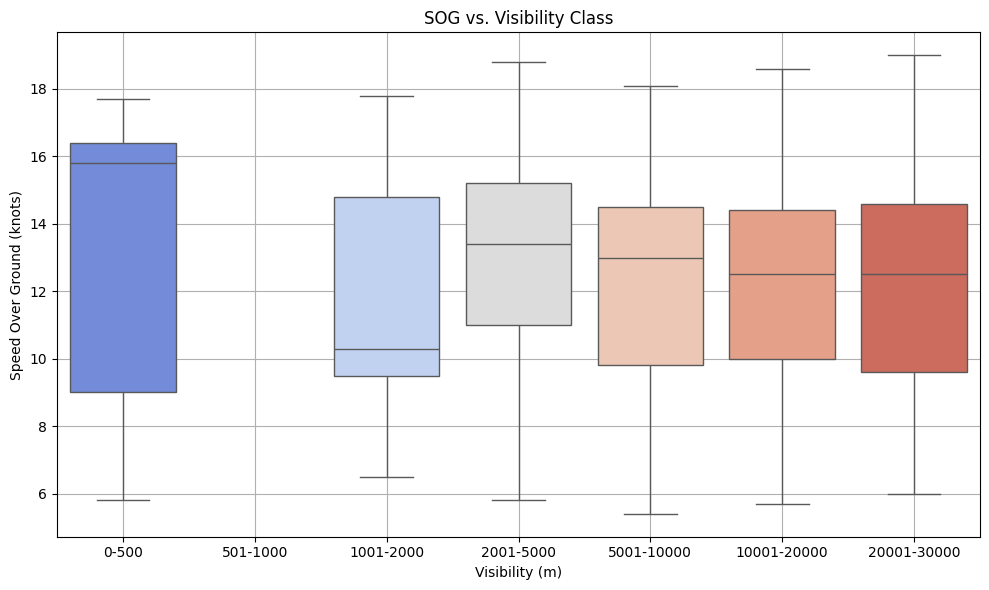


📊 Mean, Median, Count SOG by Visibility Class:
  visibility_class       mean  median  count
0            0-500  12.709659    15.8    352
1        1001-2000  11.425483    10.3    828
2        2001-5000  12.971135    13.4  12614
3       5001-10000  12.333981    13.0  16515
4      10001-20000  12.267412    12.5  27298
5      20001-30000  12.371936    12.5  29771

🚢 Ship Types in Each Visibility Class:
  visibility_class                ship_types_present
0            0-500                  [70, 71, 73, 74]
1        1001-2000              [70, 71, 73, 74, 79]
2        2001-5000          [70, 71, 72, 73, 74, 79]
3       5001-10000  [70, 71, 72, 73, 74, 75, 76, 79]
4      10001-20000      [70, 71, 72, 74, 75, 76, 79]
5      20001-30000  [70, 71, 72, 73, 74, 76, 78, 79]


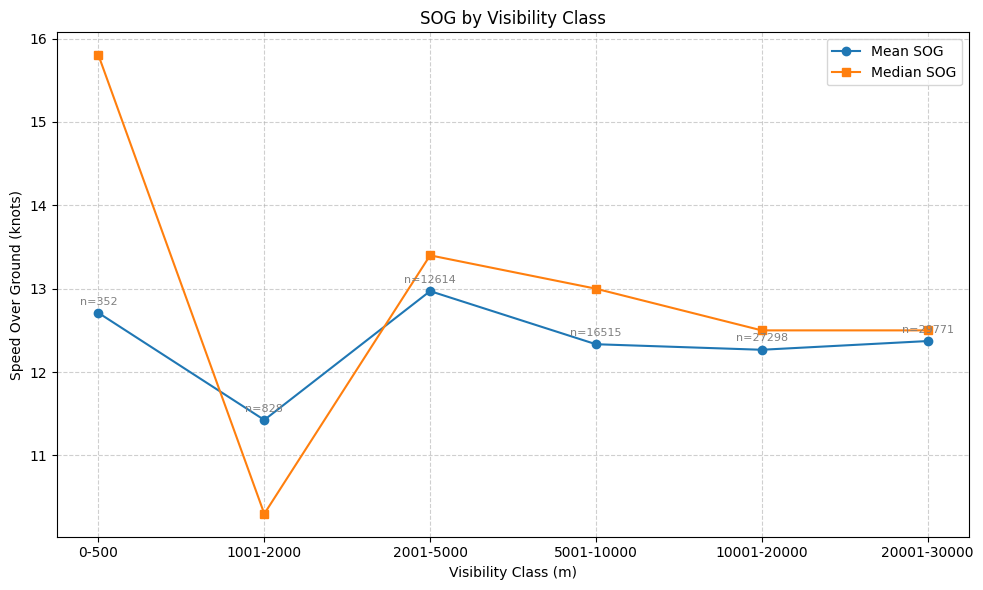


📊 Mean, Median, Count SOG by Visibility × Direction (Cargo):
   visibility_class direction       mean  median  count
0             0-500   inbound  16.475635    16.4    197
1             0-500  outbound   7.923226     9.0    155
2         1001-2000   inbound  11.753974    10.4    541
3         1001-2000  outbound  10.806272     9.2    287
4         2001-5000   inbound  13.543292    14.2   7089
5         2001-5000  outbound  12.237014    13.0   5525
6        5001-10000   inbound  13.014486    13.8   8201
7        5001-10000  outbound  11.662726    12.5   8314
8       10001-20000   inbound  12.287076    12.8  14059
9       10001-20000  outbound  12.246529    12.2  13239
10      20001-30000   inbound  12.891326    13.1  14388
11      20001-30000  outbound  11.886141    12.0  15383


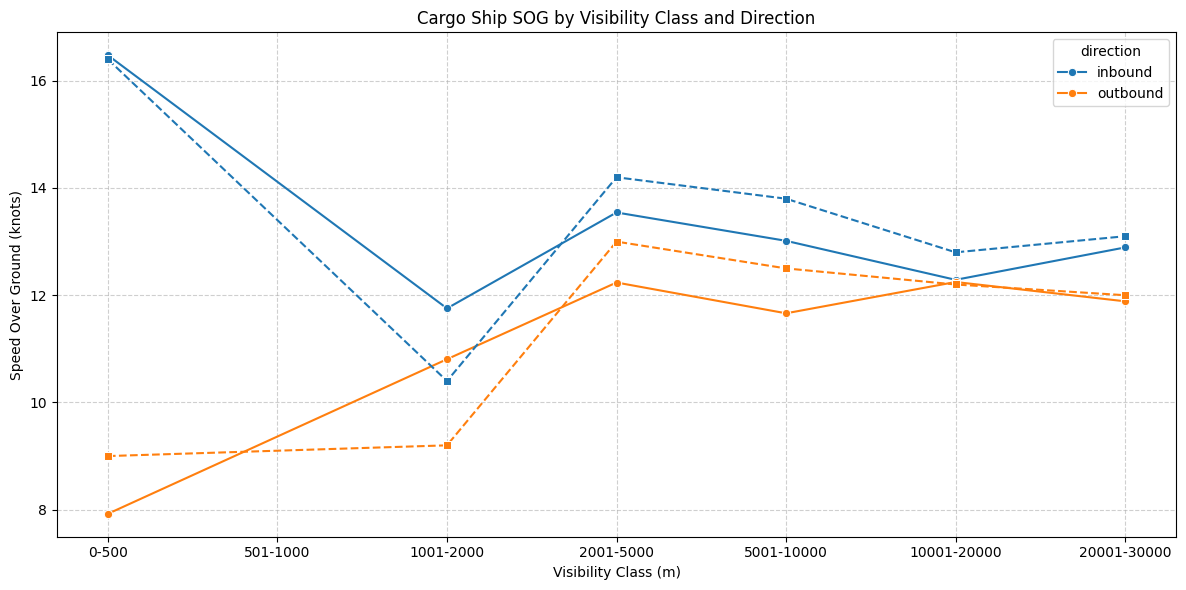


📊 Filtered Mean, Median, Count SOG by Visibility × Direction (Cargo):
   visibility_class direction       mean  median  count
0             0-500   inbound  16.475635    16.4    197
1             0-500  outbound   7.923226     9.0    155
2         1001-2000   inbound  11.753974    10.4    541
3         1001-2000  outbound  10.806272     9.2    287
4         2001-5000   inbound  13.543292    14.2   7089
5         2001-5000  outbound  12.237014    13.0   5525
6        5001-10000   inbound  13.014486    13.8   8201
7        5001-10000  outbound  11.662726    12.5   8314
8       10001-20000   inbound  12.287076    12.8  14059
9       10001-20000  outbound  12.246529    12.2  13239
10      20001-30000   inbound  12.891326    13.1  14388
11      20001-30000  outbound  11.886141    12.0  15383


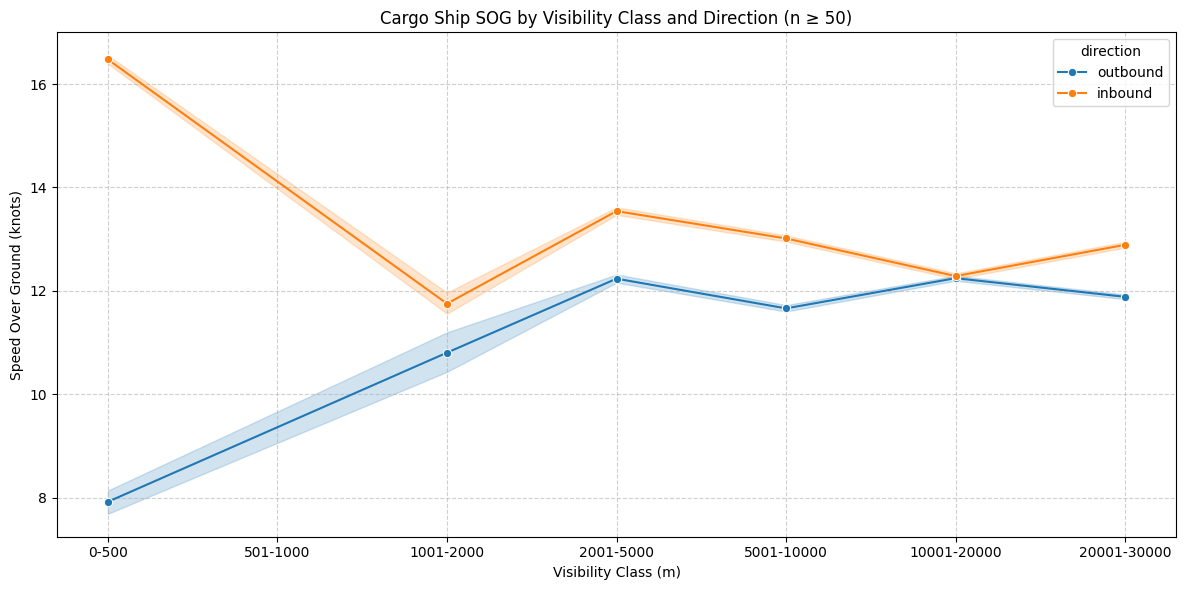

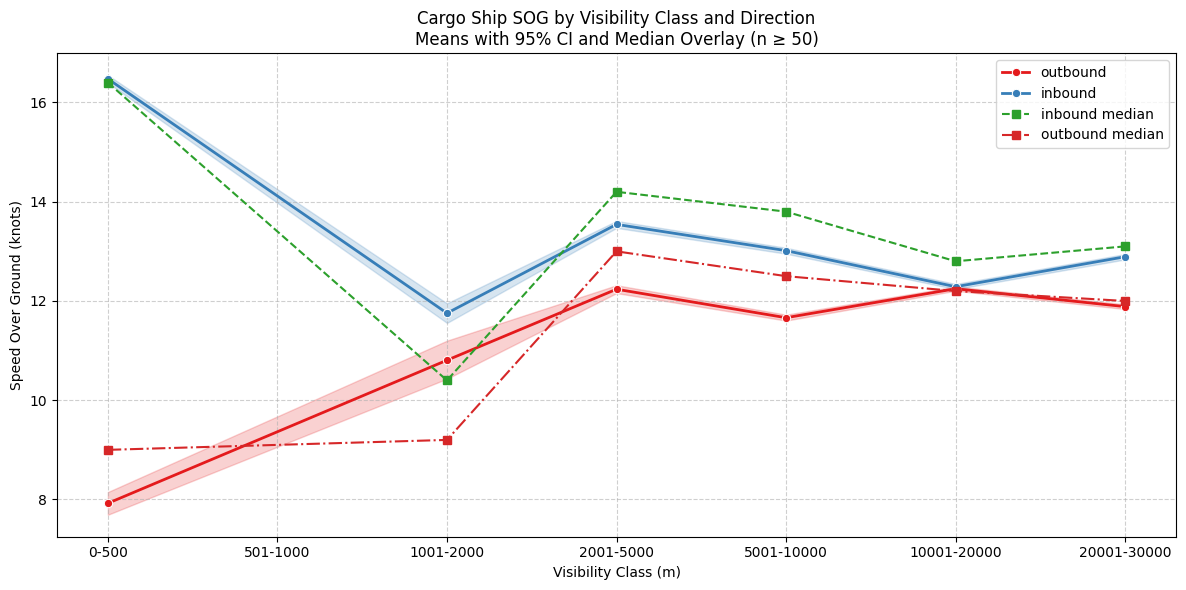

In [ ]:
import mysql.connector
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# --- DB config ---
db_config = {
    "host": "localhost",
    "user": "root",
    "password": "AMS_ship_traj03",
    "database": "ship_data",
}

# --- Load relevant columns with filters ---
def load_visibility_data():
    cnx = mysql.connector.connect(**db_config)
    query = """
        SELECT sog, visibility, beam_category, ship_type, navigational_status,cog
        FROM ais_open_water_polygon_env
        WHERE visibility IS NOT NULL AND sog IS NOT NULL
            AND visibility < 30000 AND sog > 1.0
            AND navigational_status = 0
           AND ship_type BETWEEN 70 AND 79   -- cargo ships
            and sog<30
            and ship_type not in (40,51)
            
    """
    df = pd.read_sql(query, cnx)
    cnx.close()
    return df

df = load_visibility_data()

# --- Bin visibility ---
df["visibility_class"] = pd.cut(
    df["visibility"],
    bins=[0, 500, 1000, 2000, 5000, 10000, 20000, 30000],
    labels=["0-500", "501-1000", "1001-2000", "2001-5000", "5001-10000", "10001-20000", "20001-30000"]
)

# --- Plot SOG by visibility class ---
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="visibility_class", y="sog", palette="coolwarm")
plt.title("SOG vs. Visibility Class")
plt.xlabel("Visibility (m)")
plt.ylabel("Speed Over Ground (knots)")
plt.grid(True)
plt.tight_layout()
plt.show()

# --- Grouped stats: mean, median, count ---
group_stats = df.groupby("visibility_class", observed=True)["sog"].agg(['mean', 'median', 'count']).reset_index()
print("\n📊 Mean, Median, Count SOG by Visibility Class:")
print(group_stats)

# --- Ship types per visibility class ---
ship_types_by_bin = df.groupby("visibility_class", observed=True)["ship_type"].apply(lambda x: sorted(x.unique().tolist())).reset_index()
ship_types_by_bin.rename(columns={"ship_type": "ship_types_present"}, inplace=True)
print("\n🚢 Ship Types in Each Visibility Class:")
print(ship_types_by_bin)

import matplotlib.pyplot as plt
# Columns: visibility_class, mean, median, count

plt.figure(figsize=(10,6))

# Plot mean
plt.plot(group_stats["visibility_class"], group_stats["mean"], marker="o", label="Mean SOG", color="tab:blue")

# Plot median
plt.plot(group_stats["visibility_class"], group_stats["median"], marker="s", label="Median SOG", color="tab:orange")

# Add counts as text annotations above mean points
for i, row in group_stats.iterrows():
    plt.text(i, row["mean"]+0.1, f"n={row['count']}", ha="center", fontsize=8, color="gray")

plt.title("SOG by Visibility Class")
plt.xlabel("Visibility Class (m)")
plt.ylabel("Speed Over Ground (knots)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()
# Load cargo-only data

# Bin visibility
df["visibility_class"] = pd.cut(
    df["visibility"],
    bins=[0, 500, 1000, 2000, 5000, 10000, 20000, 30000],
    labels=["0-500", "501-1000", "1001-2000", "2001-5000", "5001-10000", "10001-20000", "20001-30000"]
)

# Add inbound/outbound based on COG
df["direction"] = df["cog"].apply(lambda x: "inbound" if 180 <= x <= 360 else "outbound")

# Group stats
stats = (
    df.groupby(["visibility_class", "direction"], observed=True)["sog"]
    .agg(["mean", "median", "count"])
    .reset_index()
)
print("\n📊 Mean, Median, Count SOG by Visibility × Direction (Cargo):")
print(stats)

# Plot
plt.figure(figsize=(12,6))
sns.lineplot(
    data=stats,
    x="visibility_class",
    y="mean",
    hue="direction",
    marker="o"
)
sns.lineplot(
    data=stats,
    x="visibility_class",
    y="median",
    hue="direction",
    marker="s",
    linestyle="--",
    legend=False
)

plt.title("Cargo Ship SOG by Visibility Class and Direction")
plt.ylabel("Speed Over Ground (knots)")
plt.xlabel("Visibility Class (m)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

import seaborn as sns
import matplotlib.pyplot as plt

# Start from grouped stats (df_stats)
df_stats = df.groupby(
    ["visibility_class", "direction"], observed=True
)["sog"].agg(["mean", "median", "count"]).reset_index()

# ✅ Filter out low-sample bins (e.g., keep only count >= 50)
df_stats = df_stats[df_stats["count"] >= 50]

print("\n📊 Filtered Mean, Median, Count SOG by Visibility × Direction (Cargo):")
print(df_stats)

# --- Plot with seaborn lineplot + CI ---
plt.figure(figsize=(12,6))

sns.lineplot(
    data=df[df["visibility_class"].notna()],  # raw data for CI calc
    x="visibility_class",
    y="sog",
    hue="direction",
    errorbar="ci",   # 95% confidence interval
    marker="o"
)

plt.title("Cargo Ship SOG by Visibility Class and Direction (n ≥ 50)")
plt.ylabel("Speed Over Ground (knots)")
plt.xlabel("Visibility Class (m)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,6))

# Lineplot with CI bands (mean ± 95% CI)
sns.lineplot(
    data=df[df["visibility_class"].notna()],
    x="visibility_class",
    y="sog",
    hue="direction",
    errorbar="ci",
    marker="o",
    linewidth=2,
    palette="Set1"
)

# Overlay medians from grouped stats (dashed lines)
for direction, style in zip(["inbound", "outbound"], ["--", "-."]):
    subset = df_stats[df_stats["direction"] == direction]
    plt.plot(
        subset["visibility_class"],
        subset["median"],
        linestyle=style,
        marker="s",
        label=f"{direction} median"
    )

plt.title("Cargo Ship SOG by Visibility Class and Direction\nMeans with 95% CI and Median Overlay (n ≥ 50)")
plt.ylabel("Speed Over Ground (knots)")
plt.xlabel("Visibility Class (m)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


In [2]:
import pandas as pd
import mysql.connector

# DB config
db_config = {
    "host": "localhost",
    "user": "root",
    "password": "AMS_ship_traj03",
    "database": "ship_data",
}

# Load encounter table
def load_encounters():
    cnx = mysql.connector.connect(**db_config)
    df = pd.read_sql("SELECT * FROM ais_open_water_polygon_enc", cnx)  # replace with actual name
    cnx.close()
    return df

# Load environment table
def load_environment():
    cnx = mysql.connector.connect(**db_config)
    df = pd.read_sql("SELECT id, sog, wind_hindered, current_hindered, visibility FROM ais_open_water_polygon_env", cnx)
    cnx.close()
    return df

enc_df = load_encounters()
env_df = load_environment()


# Ensure id_1 and id_2 are integers for merging
enc_df["id_1"] = enc_df["id_1"].astype(int)
enc_df["id_2"] = enc_df["id_2"].astype(int)

# Merge environmental data for both ship1 and ship2
enc_df = enc_df.merge(env_df.add_suffix("_1"), left_on="id_1", right_on="id_1", how="left")
enc_df = enc_df.merge(env_df.add_suffix("_2"), left_on="id_2", right_on="id_2", how="left")


# Hindrance if either ship is affected
enc_df["wind_hindered"] = enc_df["wind_hindered_1"].eq("yes") | enc_df["wind_hindered_2"].eq("yes")
enc_df["current_hindered"] = enc_df["current_hindered_1"].eq("yes") | enc_df["current_hindered_2"].eq("yes")
enc_df["low_visibility"] = (enc_df["visibility_1"] < 2000) | (enc_df["visibility_2"] < 2000)

# Average SOG
enc_df["avg_sog"] = (enc_df["sog_1"] + enc_df["sog_2"]) / 2


# Summary by encounter type and hindrance
summary = enc_df.groupby(["encounter_type", "wind_hindered", "current_hindered", "low_visibility"]).agg(
    encounter_count=("id_1", "count"),
    mean_sog=("avg_sog", "mean")
).reset_index()

print(summary)


C:\Users\cvais\AppData\Local\Temp\ipykernel_7500\785942498.py:15: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql("SELECT * FROM ais_open_water_polygon_enc", cnx)  # replace with actual name
C:\Users\cvais\AppData\Local\Temp\ipykernel_7500\785942498.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql("SELECT id, sog, wind_hindered, current_hindered, visibility FROM ais_open_water_polygon_env", cnx)


       encounter_type  wind_hindered  current_hindered  low_visibility  \
0       crossing_port          False             False           False   
1       crossing_port           True             False           False   
2       crossing_port           True              True           False   
3  crossing_starboard          False             False           False   
4             head-on          False             False           False   
5             head-on           True              True           False   
6          overtaking          False             False           False   
7          overtaking           True             False           False   

   encounter_count  mean_sog  
0               15    11.070  
1                6    11.600  
2               10    11.815  
3                7    10.650  
4                2    14.000  
5                5    11.670  
6                6     7.850  
7                1     5.850  


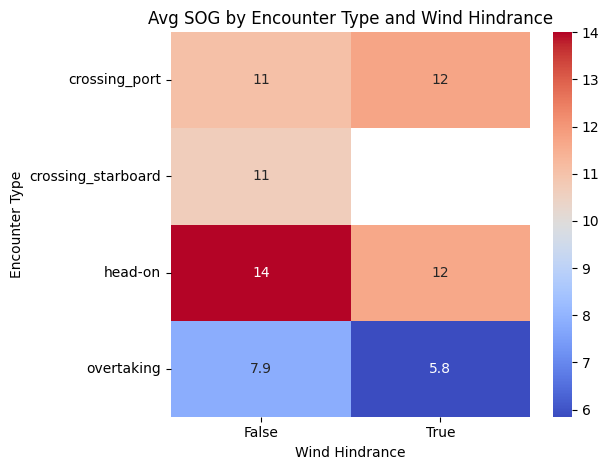

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

pivot = enc_df.groupby(["encounter_type", "wind_hindered"])["avg_sog"].mean().unstack()
sns.heatmap(pivot, annot=True, cmap="coolwarm")
plt.title("Avg SOG by Encounter Type and Wind Hindrance")
plt.xlabel("Wind Hindrance")
plt.ylabel("Encounter Type")
plt.tight_layout()
plt.show()


C:\Users\cvais\AppData\Local\Temp\ipykernel_16360\1615469845.py:19: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, cnx)


wind_hindered
no     0.103437
yes    0.107889
Name: turn_rate, dtype: float64


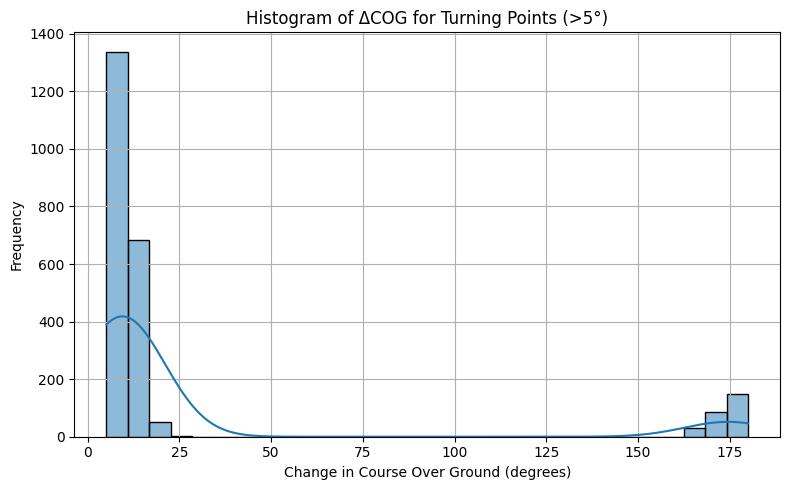

In [2]:
import mysql.connector
import pandas as pd

db_config = {
    "host": "localhost",
    "user": "root",
    "password": "AMS_ship_traj03",
    "database": "ship_data",
}

def load_cog_data():
    cnx = mysql.connector.connect(**db_config)
    query = """
        SELECT mmsi, timestamp_ais, cog, wind_hindered,sog
        FROM ais_open_water_polygon_env
        WHERE cog IS NOT NULL AND wind_hindered IS NOT NULL and ship_type =70 and navigational_status = 0
        ORDER BY mmsi, timestamp_ais
    """
    df = pd.read_sql(query, cnx)
    cnx.close()
    return df

df = load_cog_data()


# Ensure correct type and sorting
df["timestamp_ais"] = pd.to_datetime(df["timestamp_ais"])
df.sort_values(by=["mmsi", "timestamp_ais"], inplace=True)

# Compute ΔCOG
df["delta_cog"] = df.groupby("mmsi")["cog"].diff().abs()

# Normalize wrap-around values (>180° becomes 360 - Δ)
df["delta_cog"] = df["delta_cog"].apply(lambda x: 360 - x if x > 180 else x)

TURN_THRESHOLD = 5  # degrees

df["is_turn"] = df["delta_cog"] > TURN_THRESHOLD

turn_summary = df.groupby(["mmsi", "wind_hindered"]).agg(
    total_points=("delta_cog", "count"),
    turn_count=("is_turn", "sum")
).reset_index()

turn_summary["turn_rate"] = turn_summary["turn_count"] / turn_summary["total_points"]


print(turn_summary.groupby("wind_hindered")["turn_rate"].mean())

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(df[df["is_turn"]]["delta_cog"], bins=30, kde=True)
plt.title("Histogram of ΔCOG for Turning Points (>5°)")
plt.xlabel("Change in Course Over Ground (degrees)")
plt.ylabel("Frequency")
plt.grid(True)
plt.tight_layout()
plt.show()


Text(0.5, 1.0, 'Turn Angle (ΔCOG) Distribution by Wind Hindrance')

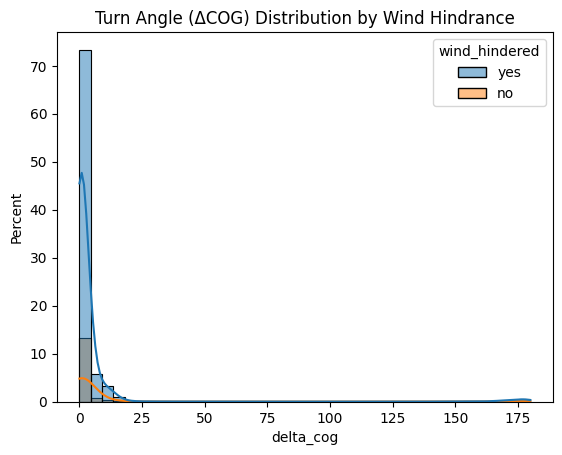

In [13]:
sns.histplot(data=df, x="delta_cog", bins=40, hue="wind_hindered", kde=True, stat="percent")
plt.title("Turn Angle (ΔCOG) Distribution by Wind Hindrance")


Text(0.5, 0, 'Wind Hindrance')

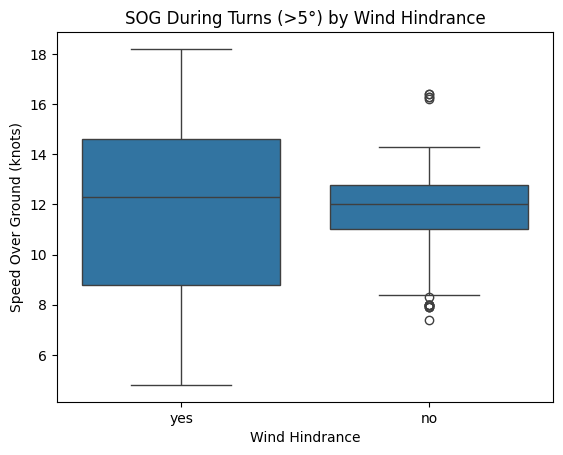

In [19]:
df_turns = df[df["is_turn"]]
sns.boxplot(data=df_turns, x="wind_hindered", y="sog")
plt.title("SOG During Turns (>5°) by Wind Hindrance")
plt.ylabel("Speed Over Ground (knots)")
plt.xlabel("Wind Hindrance")


Speed to destination

cog vs wind and beam

C:\Users\cvais\AppData\Local\Temp\ipykernel_16948\3689459279.py:28: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, cnx)



Turn rate by beam and wind alignment:
       beam_category wind_alignment  total_points  turn_count  turn_rate
0  10m <= Beam < 23m       headwind         22741        2693   0.118420
1  10m <= Beam < 23m       tailwind          3507         416   0.118620
2  23m <= Beam < 33m       headwind         10244        1058   0.103280
3  23m <= Beam < 33m       tailwind          1699         136   0.080047
4         Beam < 10m       headwind          1034         365   0.352998
5         Beam < 10m       tailwind            98          53   0.540816
6        Beam <= 33m       headwind          6664         720   0.108043
7        Beam <= 33m       tailwind          1925         174   0.090390


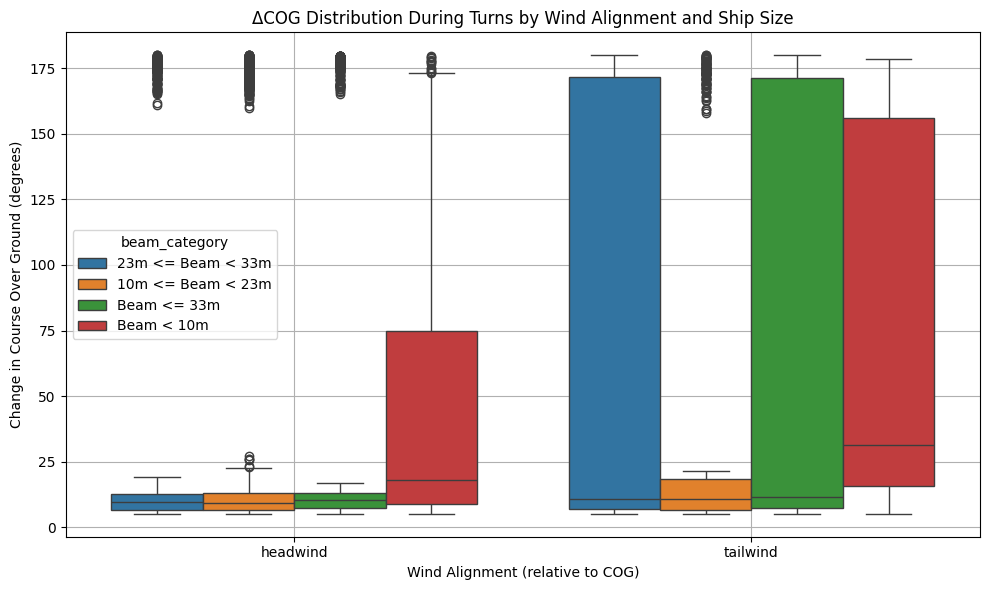

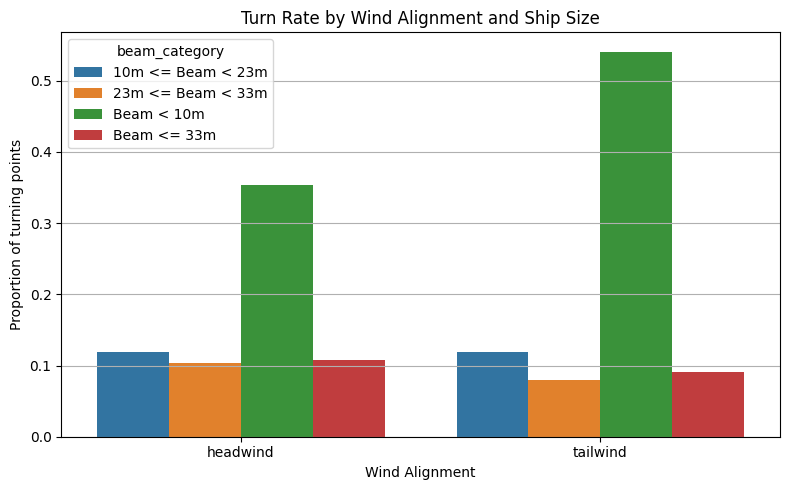

In [15]:
import mysql.connector
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

db_config = {
    "host": "localhost",
    "user": "root",
    "password": "AMS_ship_traj03",
    "database": "ship_data",
}

def load_cog_data():
    cnx = mysql.connector.connect(**db_config)
    query = """
        SELECT 
            mmsi, timestamp_ais, cog, sog,
            wind_direction_10m, wind_hindered,current_direction_deg,
            beam_m, beam_category
        FROM ais_open_water_polygon_env
        WHERE cog IS NOT NULL 
          AND wind_hindered IS NOT NULL
          AND ship_type bETWEEN 60 AND 80
          AND navigational_status = 0
        ORDER BY mmsi, timestamp_ais
    """
    df = pd.read_sql(query, cnx)
    cnx.close()
    return df

df = load_cog_data()

# Ensure correct types
df["timestamp_ais"] = pd.to_datetime(df["timestamp_ais"])
df.sort_values(by=["mmsi", "timestamp_ais"], inplace=True)

# --- ΔCOG ---
df["delta_cog"] = df.groupby("mmsi")["cog"].diff().abs()
df["delta_cog"] = df["delta_cog"].apply(lambda x: 360 - x if x > 180 else x)

TURN_THRESHOLD = 5  # degrees
df["is_turn"] = df["delta_cog"] > TURN_THRESHOLD

# --- Wind alignment wrt COG ---
def classify_wind_alignment(cog, wind_dir):
    if pd.isna(cog) or pd.isna(wind_dir):
        return np.nan
    angle = (wind_dir - cog + 360) % 360
    if angle <= 45 or angle >= 315:
        return "tailwind"
    elif 135 <= angle <= 225:
        return "headwind"
    else:
        return "crosswind"

df["wind_alignment"] = df.apply(lambda r: classify_wind_alignment(r["cog"], r["wind_direction_10m"]), axis=1)

# --- Turn summary by beam and wind alignment ---
turn_summary = (
    df.groupby(["beam_category", "wind_alignment"])
      .agg(total_points=("delta_cog", "count"),
           turn_count=("is_turn", "sum"))
      .reset_index()
)

turn_summary["turn_rate"] = turn_summary["turn_count"] / turn_summary["total_points"]

print("\nTurn rate by beam and wind alignment:")
print(turn_summary)

# --- Visualization ---
plt.figure(figsize=(10, 6))
sns.boxplot(data=df[df["is_turn"]], x="wind_alignment", y="delta_cog", hue="beam_category")
plt.title("ΔCOG Distribution During Turns by Wind Alignment and Ship Size")
plt.xlabel("Wind Alignment (relative to COG)")
plt.ylabel("Change in Course Over Ground (degrees)")
plt.grid(True)
plt.tight_layout()
plt.show()

# Optional: Turn rate barplot
plt.figure(figsize=(8,5))
sns.barplot(data=turn_summary, x="wind_alignment", y="turn_rate", hue="beam_category")
plt.title("Turn Rate by Wind Alignment and Ship Size")
plt.ylabel("Proportion of turning points")
plt.xlabel("Wind Alignment")
plt.grid(True, axis="y")
plt.tight_layout()
plt.show()


cog is by wind or current 

In [16]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

# --- Relative wind/current alignment ---
def classify_alignment(angle):
    if pd.isna(angle):
        return np.nan
    if angle <= 45 or angle >= 315:
        return "tail"
    elif 135 <= angle <= 225:
        return "head"
    else:
        return "cross"

# Wind
df["rel_wind_angle"] = (df["wind_direction_10m"] - df["cog"] + 360) % 360
df["wind_align"] = df["rel_wind_angle"].apply(classify_alignment)

# Current
df["rel_curr_angle"] = (df["current_direction_deg"] - df["cog"] + 360) % 360
df["curr_align"] = df["rel_curr_angle"].apply(classify_alignment)

# --- Turn classification already present ---
df["is_turn"] = (df["delta_cog"] > 5).astype(int)

# --- Add ship size + speed bands ---
df["sog_band"] = pd.cut(
    df["sog"], bins=[0,6,9,12,15,40], labels=["<=6","6–9","9–12","12–15",">15"]
)

# --- Split regions by bounding box ---
def region_label(lat, lon):
    if 53.8 <= lat <= 54.1 and 8.6 <= lon <= 9.2:
        return "Cuxhaven"
    elif 48.96 <= lat <= 49.16 and 8.18 <= lon <= 8.46:
        return "Rhine_haven"
    else:
        return "Other"

df["region"] = "Cuxhaven"

# --- Group summary: turn rates by wind/current alignment ---
turn_summary = (
    df.groupby(["region","wind_align","curr_align"])
      ["is_turn"].agg(["mean","count"]).reset_index()
)
print(turn_summary)

# --- Logistic regression to test significance ---
# baseline = headwind + headcurrent
model = smf.logit(
    "is_turn ~ C(wind_align) + C(curr_align) + C(beam_category) + C(sog_band) + C(region)",
    data=df[df["region"].isin(["Cuxhaven","Rhine_haven"])]
).fit()

print(model.summary())

# --- Odds ratios ---
odds_ratios = pd.DataFrame({
    "OR": np.exp(model.params),
    "CI_lower": np.exp(model.conf_int()[0]),
    "CI_upper": np.exp(model.conf_int()[1])
})
print(odds_ratios)


     region wind_align curr_align      mean  count
0  Cuxhaven       head      cross  0.123802   7512
1  Cuxhaven       head       head  0.124007  15104
2  Cuxhaven       head       tail  0.111361  18256
3  Cuxhaven       tail      cross  0.112500    720
4  Cuxhaven       tail       head  0.101294   3169
5  Cuxhaven       tail       tail  0.111209   3390
Optimization terminated successfully.
         Current function value: 0.354274
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:                is_turn   No. Observations:                48151
Model:                          Logit   Df Residuals:                    48140
Method:                           MLE   Df Model:                           10
Date:                Sat, 20 Sep 2025   Pseudo R-squ.:                 0.01623
Time:                        11:57:23   Log-Likelihood:                -17059.
converged:                       True   LL-Null:                   

C:\Users\cvais\AppData\Local\Temp\ipykernel_16948\2022691275.py:6: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.barplot(


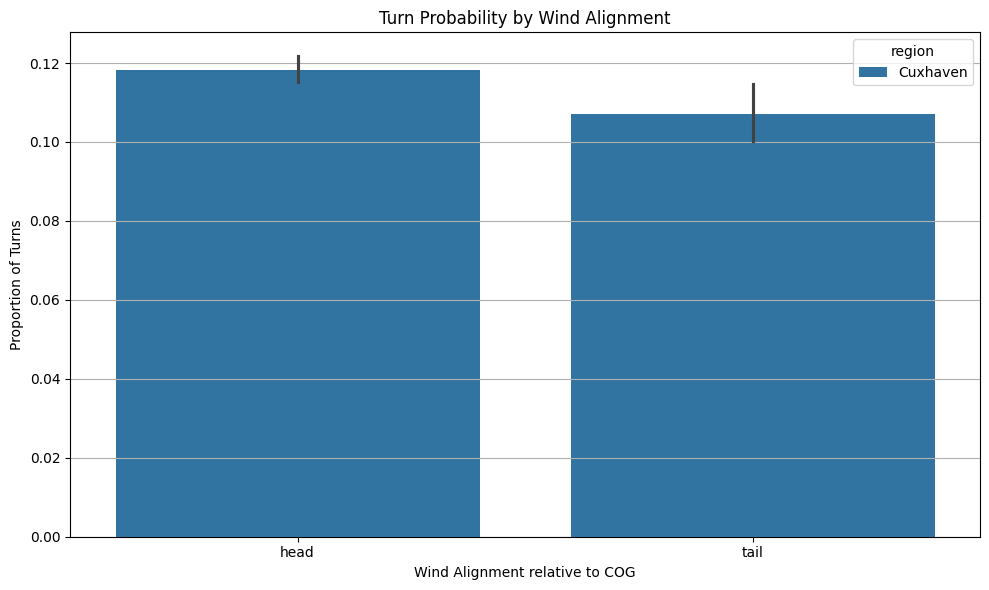

C:\Users\cvais\AppData\Local\Temp\ipykernel_16948\2022691275.py:19: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.barplot(


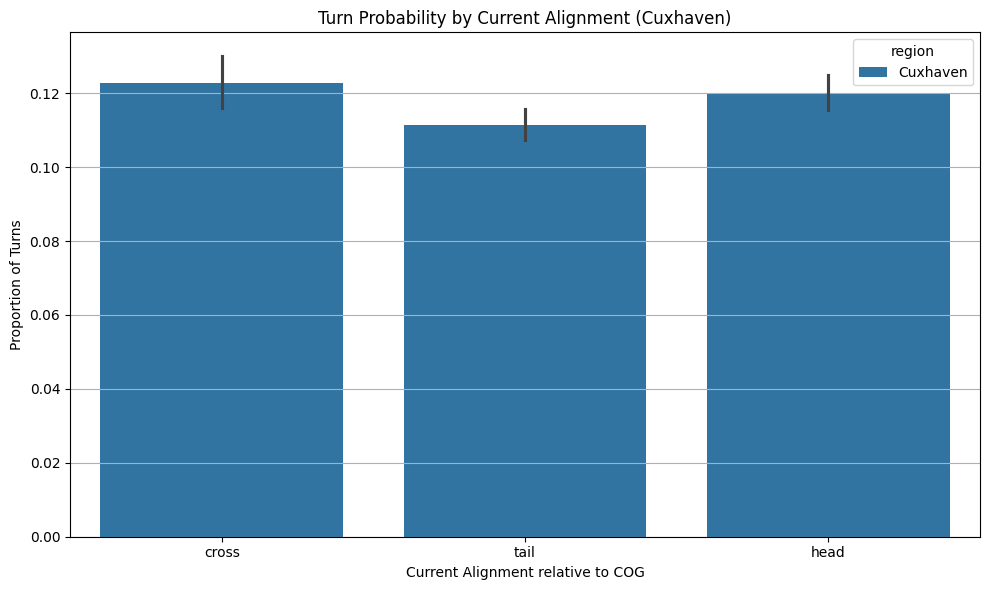

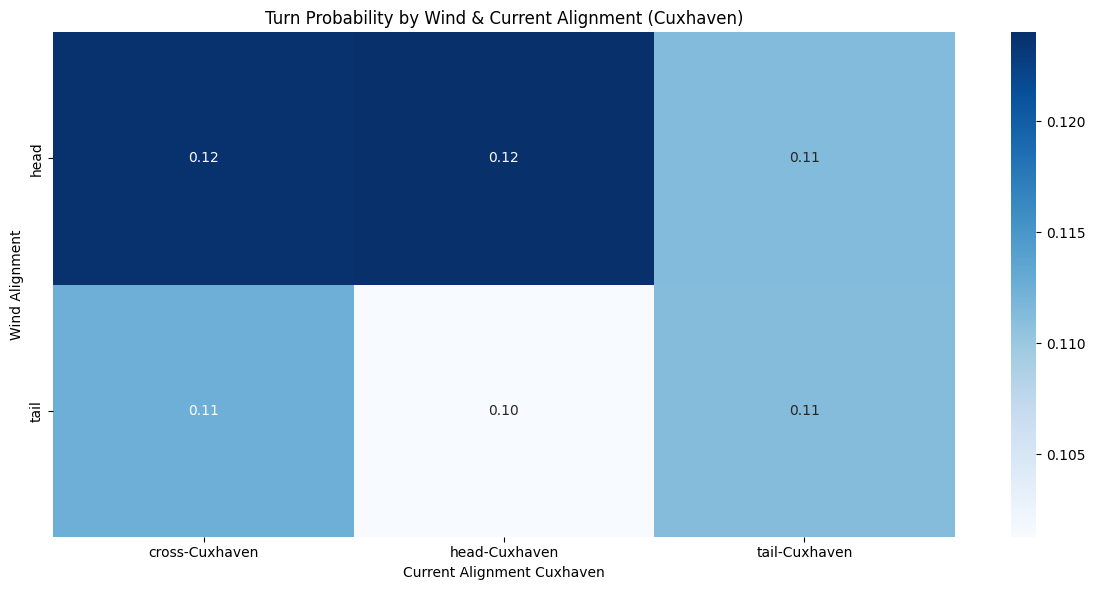

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- Turn probability by wind alignment and region ---
plt.figure(figsize=(10,6))
sns.barplot(
    data=df[df["region"].isin(["Cuxhaven","Rhine_haven"])],
    x="wind_align", y="is_turn", hue="region", estimator="mean", ci=95
)
plt.title("Turn Probability by Wind Alignment")
plt.ylabel("Proportion of Turns")
plt.xlabel("Wind Alignment relative to COG")
plt.grid(True, axis="y")
plt.tight_layout()
plt.show()

# --- Turn probability by current alignment and region ---
plt.figure(figsize=(10,6))
sns.barplot(
    data=df[df["region"].isin(["Cuxhaven"])],
    x="curr_align", y="is_turn", hue="region", estimator="mean", ci=95
)
plt.title("Turn Probability by Current Alignment (Cuxhaven)")
plt.ylabel("Proportion of Turns")
plt.xlabel("Current Alignment relative to COG")
plt.grid(True, axis="y")
plt.tight_layout()
plt.show()

# --- Combined heatmap for interactions ---
turn_matrix = (
    df[df["region"].isin(["Cuxhaven"])]
    .groupby(["region","wind_align","curr_align"])["is_turn"]
    .mean()
    .reset_index()
    .pivot_table(index=["wind_align"], columns=["curr_align","region"], values="is_turn")
)

plt.figure(figsize=(12,6))
sns.heatmap(turn_matrix, annot=True, cmap="Blues", fmt=".2f")
plt.title("Turn Probability by Wind & Current Alignment (Cuxhaven)")
plt.ylabel("Wind Alignment")
plt.xlabel("Current Alignment Cuxhaven")
plt.tight_layout()
plt.show()


COG Regression

In [18]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import pandas as pd
import mysql.connector

# ---- Load data with wind + size ----
def load_cog_data():
    cnx = mysql.connector.connect(**db_config)
    query = """
        SELECT mmsi, datetime_utc, cog, sog,
               wind_direction_10m, wind_hindered,current_direction_deg,
               beam_m, beam_category
        FROM ais_open_water_polygon_env
        WHERE cog IS NOT NULL 
          AND wind_hindered IS NOT NULL
          AND ship_type between 60 and 80
          AND navigational_status = 0
        ORDER BY mmsi, datetime_utc
    """
    df = pd.read_sql(query, cnx)
    cnx.close()
    return df

df = load_cog_data()

# ---- Preprocess ----
df["datetime_utc"] = pd.to_datetime(df["datetime_utc"])
df.sort_values(by=["mmsi", "datetime_utc"], inplace=True)

# ΔCOG + turns
df["delta_cog"] = df.groupby("mmsi")["cog"].diff().abs()
df["delta_cog"] = df["delta_cog"].apply(lambda x: 360 - x if x > 180 else x)
TURN_THRESHOLD = 5
df["is_turn"] = (df["delta_cog"] > TURN_THRESHOLD).astype(int)  # ensure 0/1

# ---- Add wind alignment wrt COG ----
def classify_wind_alignment(cog, wind_dir):
    if pd.isna(cog) or pd.isna(wind_dir):
        return np.nan
    angle = (wind_dir - cog + 360) % 360
    if angle <= 45 or angle >= 315:
        return "tailwind"
    elif 135 <= angle <= 225:
        return "headwind"
    else:
        return "crosswind"

df["wind_alignment"] = df.apply(
    lambda r: classify_wind_alignment(r["cog"], r["wind_direction_10m"]), axis=1
)

# ---- Add direction (inbound/outbound from COG) ----
def classify_direction(cog):
    if pd.isna(cog):
        return np.nan
    return "inbound" if 180 <= cog <= 360 else "outbound"

df["direction"] = df["cog"].apply(classify_direction)

# ---- Bin speeds into categories ----
df["sog_band"] = pd.cut(
    df["sog"], bins=[0, 6, 9, 12, 15, 40],
    labels=["<=6", "6–9", "9–12", "12–15", ">15"]
)

# ---- Drop rows with missing categories ----
df = df.dropna(subset=["wind_alignment", "beam_category", "direction", "sog_band"])

# ---- Logistic regression: probability of a turn ----
model = smf.logit(
    "is_turn ~ C(wind_alignment) * C(beam_category) + C(sog_band) + C(direction)",
    data=df
).fit()

print(model.summary())

# ---- Odds ratios (for report) ----
odds_ratios = pd.DataFrame({
    "OR": np.exp(model.params),
    "CI_lower": np.exp(model.conf_int()[0]),
    "CI_upper": np.exp(model.conf_int()[1])
})
print("\nOdds Ratios with 95% CI:\n", odds_ratios)



C:\Users\cvais\AppData\Local\Temp\ipykernel_16948\534809137.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, cnx)


Optimization terminated successfully.
         Current function value: 0.012169
         Iterations 11
                           Logit Regression Results                           
Dep. Variable:                is_turn   No. Observations:                48151
Model:                          Logit   Df Residuals:                    48138
Method:                           MLE   Df Model:                           12
Date:                Sat, 20 Sep 2025   Pseudo R-squ.:                 0.07934
Time:                        11:57:39   Log-Likelihood:                -585.93
converged:                       True   LL-Null:                       -636.43
Covariance Type:            nonrobust   LLR p-value:                 3.562e-16
                                                                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------------

Turn Probability vs speed vs direction

C:\Users\cvais\AppData\Local\Temp\ipykernel_16948\1513838893.py:24: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, cnx)



Turn probability by wind alignment and direction (Cuxhaven):
  wind_align direction  turn_prob  count
0   headwind   inbound   0.001682  23180
1   headwind  outbound   0.001639  17692
2   tailwind   inbound   0.003605   2774
3   tailwind  outbound   0.001998   4505

Turn probability under headwind (Cuxhaven):
  direction  turn_prob  count
0   inbound   0.001682  23180
1  outbound   0.001639  17692

Speed under headwind (Cuxhaven):
  direction   mean_sog  median_sog  count
0   inbound  12.967735        13.6  23180
1  outbound  11.520896        12.0  17692


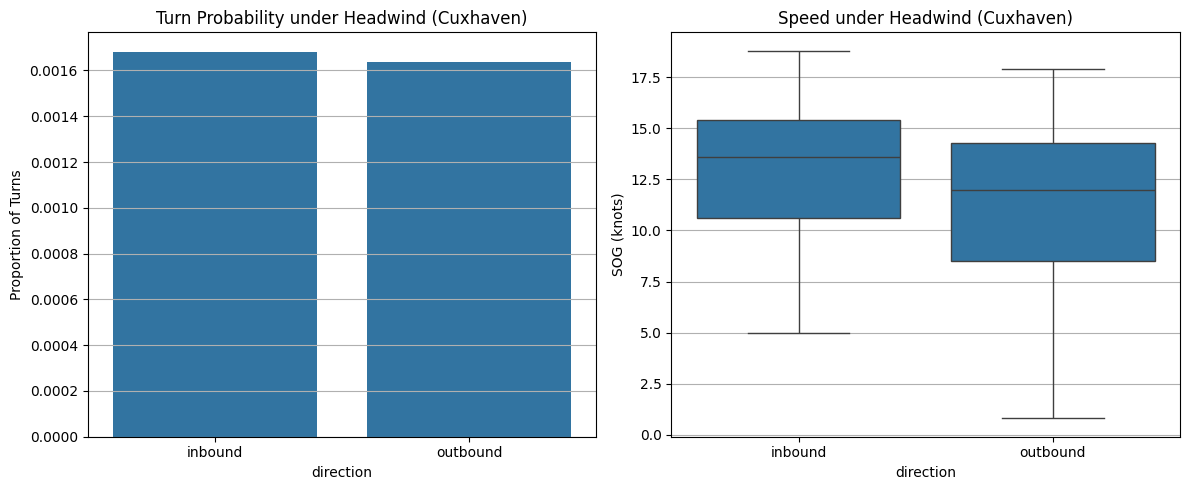

In [ ]:
import mysql.connector
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ---- Load AIS data (Cuxhaven subset from  DB) ----
def load_cux_data():
    cnx = mysql.connector.connect(**db_config)
    query = """
        SELECT mmsi, datetime_utc, cog, sog,
               wind_direction_10m, wind_hindered,
               beam_m, beam_category
        FROM ais_open_water_polygon_env
        WHERE cog IS NOT NULL
          AND wind_hindered IS NOT NULL
          AND ship_type between 60 and 80
          AND navigational_status = 0
          -- Cuxhaven bounding box
          AND latitude BETWEEN 53.8 AND 54.1
          AND longitude BETWEEN 8.6 AND 9.2
        ORDER BY mmsi, datetime_utc
    """
    df = pd.read_sql(query, cnx)
    cnx.close()
    return df

df = load_cux_data()

# ---- Preprocess ----
df["datetime_utc"] = pd.to_datetime(df["datetime_utc"])
df.sort_values(by=["mmsi","datetime_utc"], inplace=True)

# ΔCOG + turns
df["delta_cog"] = df.groupby("mmsi")["cog"].diff().abs()
df["delta_cog"] = df["delta_cog"].apply(lambda x: 360 - x if x > 180 else x)
df["is_turn"] = (df["delta_cog"] > 5).astype(int)

# ---- Wind alignment wrt COG ----
def classify_wind_alignment(cog, wind_dir):
    if pd.isna(cog) or pd.isna(wind_dir):
        return np.nan
    angle = (wind_dir - cog + 360) % 360
    if angle <= 45 or angle >= 315:
        return "tailwind"
    elif 135 <= angle <= 225:
        return "headwind"
    else:
        return "crosswind"

df["wind_align"] = df.apply(
    lambda r: classify_wind_alignment(r["cog"], r["wind_direction_10m"]), axis=1
)

# ---- Direction inbound/outbound ----
def classify_direction(cog):
    if pd.isna(cog):
        return np.nan
    return "inbound" if 180 <= cog <= 360 else "outbound"

df["direction"] = df["cog"].apply(classify_direction)

# ---- Turn probability by wind + direction ----
turn_summary = (
    df.groupby(["wind_align","direction"])["is_turn"]
      .agg(turn_prob="mean", count="count")
      .reset_index()
)
print("\nTurn probability by wind alignment and direction (Cuxhaven):")
print(turn_summary)

# ---- Focus only on headwind cases ----
headwind_df = df[df["wind_align"]=="headwind"].copy()

turn_summary_head = (
    headwind_df.groupby("direction")["is_turn"]
               .agg(turn_prob="mean", count="count")
               .reset_index()
)
print("\nTurn probability under headwind (Cuxhaven):")
print(turn_summary_head)

sog_summary_head = (
    headwind_df.groupby("direction")["sog"]
               .agg(mean_sog="mean", median_sog="median", count="count")
               .reset_index()
)
print("\nSpeed under headwind (Cuxhaven):")
print(sog_summary_head)

# ---- Visualization ----
fig, axes = plt.subplots(1,2,figsize=(12,5))

sns.barplot(data=turn_summary_head, x="direction", y="turn_prob", ax=axes[0])
axes[0].set_title("Turn Probability under Headwind (Cuxhaven)")
axes[0].set_ylabel("Proportion of Turns")
axes[0].grid(True, axis="y")

sns.boxplot(data=headwind_df, x="direction", y="sog", ax=axes[1])
axes[1].set_title("Speed under Headwind (Cuxhaven)")
axes[1].set_ylabel("SOG (knots)")
axes[1].grid(True, axis="y")

plt.tight_layout()
plt.show()


Wind

C:\Users\cvais\AppData\Local\Temp\ipykernel_16948\1513838893.py:24: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, cnx)



Turn probability by wind alignment and direction (Cuxhaven):
  wind_align direction  turn_prob  count
0   headwind   inbound   0.001682  23180
1   headwind  outbound   0.001639  17692
2   tailwind   inbound   0.003605   2774
3   tailwind  outbound   0.001998   4505

Turn probability under headwind (Cuxhaven):
  direction  turn_prob  count
0   inbound   0.001682  23180
1  outbound   0.001639  17692

Speed under headwind (Cuxhaven):
  direction   mean_sog  median_sog  count
0   inbound  12.967735        13.6  23180
1  outbound  11.520896        12.0  17692


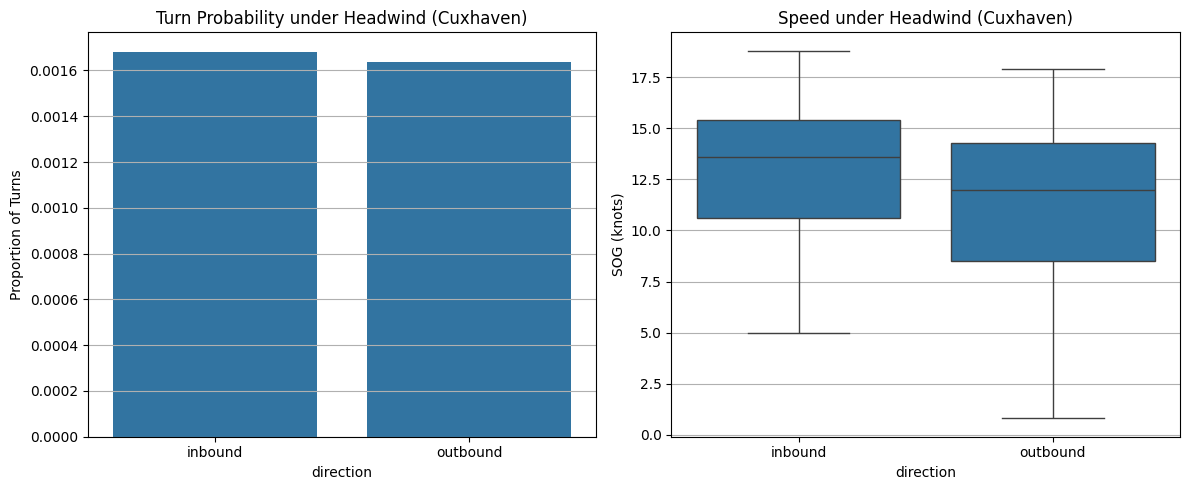

In [ ]:
import mysql.connector
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ---- Load AIS data (Cuxhaven subset from  DB) ----
def load_cux_data():
    cnx = mysql.connector.connect(**db_config)
    query = """
        SELECT mmsi, datetime_utc, cog, sog,
               wind_direction_10m, wind_hindered,
               beam_m, beam_category
        FROM ais_open_water_polygon_env
        WHERE cog IS NOT NULL
          AND wind_hindered IS NOT NULL
          AND ship_type between 60 and 80
          AND navigational_status = 0
          -- Cuxhaven bounding box
          AND latitude BETWEEN 53.8 AND 54.1
          AND longitude BETWEEN 8.6 AND 9.2
        ORDER BY mmsi, datetime_utc
    """
    df = pd.read_sql(query, cnx)
    cnx.close()
    return df

df = load_cux_data()

# ---- Preprocess ----
df["datetime_utc"] = pd.to_datetime(df["datetime_utc"])
df.sort_values(by=["mmsi","datetime_utc"], inplace=True)

# ΔCOG + turns
df["delta_cog"] = df.groupby("mmsi")["cog"].diff().abs()
df["delta_cog"] = df["delta_cog"].apply(lambda x: 360 - x if x > 180 else x)
df["is_turn"] = (df["delta_cog"] > 5).astype(int)

# ---- Wind alignment wrt COG ----
def classify_wind_alignment(cog, wind_dir):
    if pd.isna(cog) or pd.isna(wind_dir):
        return np.nan
    angle = (wind_dir - cog + 360) % 360
    if angle <= 45 or angle >= 315:
        return "tailwind"
    elif 135 <= angle <= 225:
        return "headwind"
    else:
        return "crosswind"

df["wind_align"] = df.apply(
    lambda r: classify_wind_alignment(r["cog"], r["wind_direction_10m"]), axis=1
)

# ---- Direction inbound/outbound ----
def classify_direction(cog):
    if pd.isna(cog):
        return np.nan
    return "inbound" if 180 <= cog <= 360 else "outbound"

df["direction"] = df["cog"].apply(classify_direction)

# ---- Turn probability by wind + direction ----
turn_summary = (
    df.groupby(["wind_align","direction"])["is_turn"]
      .agg(turn_prob="mean", count="count")
      .reset_index()
)
print("\nTurn probability by wind alignment and direction (Cuxhaven):")
print(turn_summary)

# ---- Focus only on headwind cases ----
headwind_df = df[df["wind_align"]=="headwind"].copy()

turn_summary_head = (
    headwind_df.groupby("direction")["is_turn"]
               .agg(turn_prob="mean", count="count")
               .reset_index()
)
print("\nTurn probability under headwind (Cuxhaven):")
print(turn_summary_head)

sog_summary_head = (
    headwind_df.groupby("direction")["sog"]
               .agg(mean_sog="mean", median_sog="median", count="count")
               .reset_index()
)
print("\nSpeed under headwind (Cuxhaven):")
print(sog_summary_head)

# ---- Visualization ----
fig, axes = plt.subplots(1,2,figsize=(12,5))

sns.barplot(data=turn_summary_head, x="direction", y="turn_prob", ax=axes[0])
axes[0].set_title("Turn Probability under Headwind (Cuxhaven)")
axes[0].set_ylabel("Proportion of Turns")
axes[0].grid(True, axis="y")

sns.boxplot(data=headwind_df, x="direction", y="sog", ax=axes[1])
axes[1].set_title("Speed under Headwind (Cuxhaven)")
axes[1].set_ylabel("SOG (knots)")
axes[1].grid(True, axis="y")

plt.tight_layout()
plt.show()


current

C:\Users\cvais\AppData\Local\Temp\ipykernel_16948\2852331966.py:21: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, cnx)



Turn probability by current alignment and direction (Cuxhaven):
     curr_align direction  turn_prob  count
0  crosscurrent   inbound   0.004023  14170
1  crosscurrent  outbound   0.001010  12874
2   headcurrent   inbound   0.002862  32149
3   headcurrent  outbound   0.001746  32081
4   tailcurrent   inbound   0.002237  36208
5   tailcurrent  outbound   0.002022  44022

Speed by current alignment and direction (Cuxhaven):
     curr_align direction   mean_sog  median_sog  count
0  crosscurrent   inbound  13.314644        14.0  14170
1  crosscurrent  outbound  10.368052        10.2  12874
2   headcurrent   inbound  11.406193        11.5  32149
3   headcurrent  outbound  10.793750        11.2  32081
4   tailcurrent   inbound  13.975284        14.5  36208
5   tailcurrent  outbound  12.476875        12.8  44022


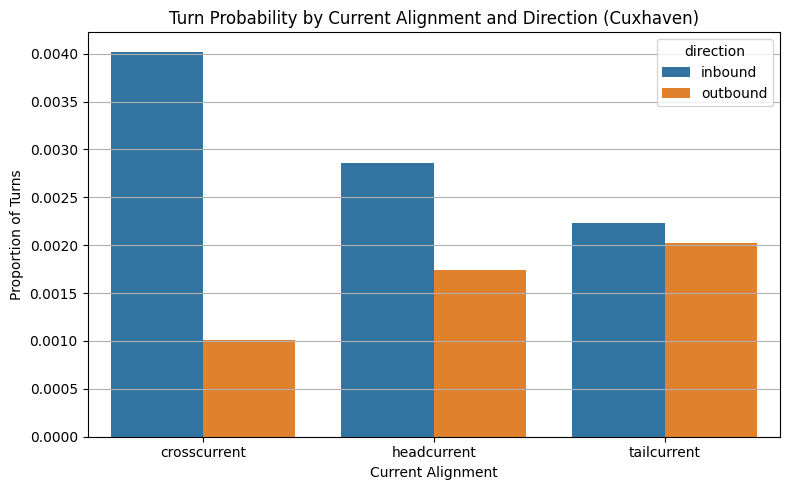

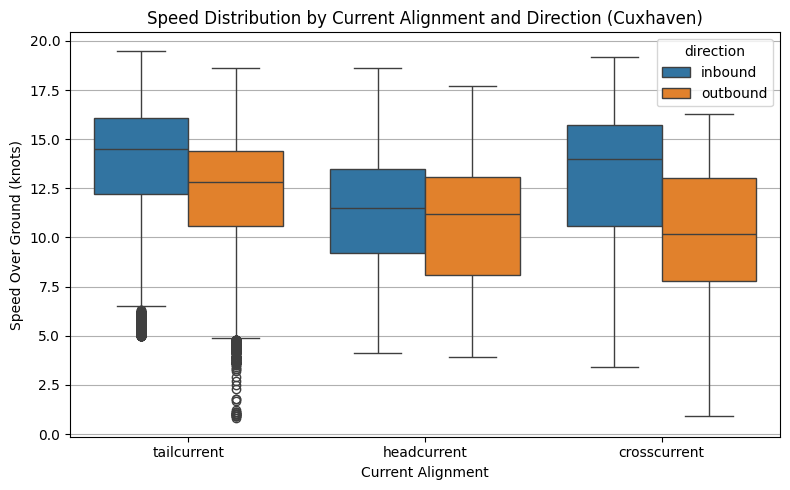

In [23]:
import mysql.connector
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# ---- Load AIS + environment data (Cuxhaven) ----
def load_cux_data():
    cnx = mysql.connector.connect(**db_config)
    query = """
        SELECT mmsi, datetime_utc, latitude, longitude,
               cog, sog, wind_direction_10m, current_direction_deg,
               beam_m, beam_category
        FROM ais_open_water_polygon_env
        WHERE cog IS NOT NULL
          AND current_direction_deg IS NOT NULL
          AND ship_type between 60 AND 80
          AND navigational_status = 0 and sog<30
        ORDER BY mmsi, datetime_utc
    """
    df = pd.read_sql(query, cnx)
    cnx.close()
    return df

df = load_cux_data()

# ---- Preprocess ----
df["datetime_utc"] = pd.to_datetime(df["datetime_utc"])
df.sort_values(by=["mmsi","datetime_utc"], inplace=True)

# ΔCOG + turns
df["delta_cog"] = df.groupby("mmsi")["cog"].diff().abs()
df["delta_cog"] = df["delta_cog"].apply(lambda x: 360 - x if x > 180 else x)
df["is_turn"] = (df["delta_cog"] > 5).astype(int)

# ---- Current alignment wrt COG ----
def classify_current_alignment(cog, curr_dir):
    if pd.isna(cog) or pd.isna(curr_dir):
        return np.nan
    angle = (curr_dir - cog + 360) % 360
    if angle <= 45 or angle >= 315:
        return "tailcurrent"
    elif 135 <= angle <= 225:
        return "headcurrent"
    else:
        return "crosscurrent"

df["curr_align"] = df.apply(
    lambda r: classify_current_alignment(r["cog"], r["current_direction_deg"]), axis=1
)

# ---- Direction inbound/outbound ----
def classify_direction(cog):
    if pd.isna(cog):
        return np.nan
    return "inbound" if 180 <= cog <= 360 else "outbound"

df["direction"] = df["cog"].apply(classify_direction)

# ---- Turn probability by current alignment + direction ----
turn_summary = (
    df.groupby(["curr_align","direction"])["is_turn"]
      .agg(turn_prob="mean", count="count")
      .reset_index()
)
print("\nTurn probability by current alignment and direction (Cuxhaven):")
print(turn_summary)

# ---- Speed by current alignment + direction ----
sog_summary = (
    df.groupby(["curr_align","direction"])["sog"]
      .agg(mean_sog="mean", median_sog="median", count="count")
      .reset_index()
)
print("\nSpeed by current alignment and direction (Cuxhaven):")
print(sog_summary)

# ---- Visualization: Turn probability ----
plt.figure(figsize=(8,5))
sns.barplot(data=turn_summary, x="curr_align", y="turn_prob", hue="direction")
plt.title("Turn Probability by Current Alignment and Direction (Cuxhaven)")
plt.ylabel("Proportion of Turns")
plt.xlabel("Current Alignment")
plt.grid(True, axis="y")
plt.tight_layout()
plt.show()

# ---- Visualization: Speed ----
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="curr_align", y="sog", hue="direction")
plt.title("Speed Distribution by Current Alignment and Direction (Cuxhaven)")
plt.ylabel("Speed Over Ground (knots)")
plt.xlabel("Current Alignment")
plt.grid(True, axis="y")
plt.tight_layout()
plt.show()
